FINAL CAPSTONE

In [ ]:
import numpy as np
import pandas as pd

In [2]:
from google.colab import files
uploaded = files.upload()


Saving Ghana_Tourism_500_Visitor_Dataset.csv to Ghana_Tourism_500_Visitor_Dataset.csv


In [3]:
import pandas as pd
tourism = pd.read_csv("Ghana_Tourism_500_Visitor_Dataset.csv")

In [4]:
tourism.head()

,Visitor_ID,Site_Name,Region,Visitor_Type,Origin,Age_Group,Gender,Purpose_of_Visit,Month_of_Visit,Season,...,Accessibility_Airport_km,Accessibility_City_km,Accommodation_Available,Event_Association,Marketing_Visibility,Average_Expenditure,Total_Expenditure,Length_of_Stay_Days,Currency,Satisfaction_Rating
0,VIS-0001,Boti Falls,Eastern,Domestic,Ashanti,45-54,Female,Relaxation,Oct,Rainy Season,...,109,36,No,NaN,High,133.28,133.28,1,GHS,4.6
1,VIS-0002,Mole National Park,Savannah,International,Australia,25-34,Other/Prefer not to say,Events/Festivals,Nov,Dry Season,...,430,77,No,NaN,High,450.22,450.22,1,GHS,4.1
2,VIS-0003,Accra Zoo,Greater Accra,Domestic,Eastern,35-44,Male,Nature/Adventure,Apr,Rainy Season,...,29,22,Yes,NaN,Medium,142.73,428.19,3,GHS,3.8
3,VIS-0004,Accra Zoo,Greater Accra,Domestic,Volta,25-34,Female,Nature/Adventure,Jul,Rainy Season,...,25,33,Yes,NaN,High,113.11,452.44,4,GHS,3.3
4,VIS-0005,Kwame Nkrumah Memorial Park,Greater Accra,Domestic,Western,45-54,Male,Visit Family/Friends,Sep,Rainy Season,...,1,1,Yes,NaN,Medium,137.31,411.93,3,GHS,4.6


In [ ]:
tourism.tail()

,Visitor_ID,Site_Name,Region,Visitor_Type,Origin,Age_Group,Gender,Purpose_of_Visit,Month_of_Visit,Season,...,Accessibility_Airport_km,Accessibility_City_km,Accommodation_Available,Event_Association,Marketing_Visibility,Average_Expenditure,Total_Expenditure,Length_of_Stay_Days,Currency,Satisfaction_Rating
495,VIS-0496,Accra Zoo,Greater Accra,Domestic,Greater Accra,25-34,Female,Historical/Educational,Jul,Rainy Season,...,1,6,No,Public Holiday,High,101.55,507.75,5,GHS,3.9
496,VIS-0497,Manhyia Palace,Ashanti,International,Netherlands,45-54,Male,Sightseeing,Oct,Rainy Season,...,1,15,No,NaN,Medium,428.85,1715.40,4,GHS,3.6
497,VIS-0498,Bunso Arboretum,Eastern,International,United States,65+,Other/Prefer not to say,Historical/Educational,Mar,Dry Season,...,79,13,Yes,Cultural Event,Medium,295.90,295.90,1,GHS,3.8
498,VIS-0499,National Museum of Ghana,Greater Accra,International,United States,18-24,Male,Cultural Experience,Apr,Rainy Season,...,1,1,Yes,NaN,Medium,374.58,749.16,2,GHS,4.3
499,VIS-0500,Tongo Hills and Tengzug Shrines,Upper East,International,Brazil,25-34,Male,Sightseeing,Oct,Rainy Season,...,661,28,Yes,NaN,Medium,30.00,60.00,2,GHS,3.5


In [ ]:
tourism.shape

(500, 24)

In [ ]:
# CHECKING FOR MISSING VALUES
tourism.isnull().sum()

,0
Visitor_ID,0
Site_Name,0
Region,0
Visitor_Type,0
Origin,0
Age_Group,0
Gender,0
Purpose_of_Visit,0
Month_of_Visit,0
Season,0


In [ ]:
# VERIFIED THE CLEANING
tourism["Event_Association"].isna().sum()

np.int64(326)

In [ ]:
# CHECKING WHICH WAS MISSING
tourism[tourism["Event_Association"].isna()][
    ["Visitor_Type", "Origin", "Purpose_of_Visit", "Month_of_Visit", "Event_Association"]
].head(20)

,Visitor_Type,Origin,Purpose_of_Visit,Month_of_Visit,Event_Association
0,Domestic,Ashanti,Relaxation,Oct,NaN
1,International,Australia,Events/Festivals,Nov,NaN
2,Domestic,Eastern,Nature/Adventure,Apr,NaN
3,Domestic,Volta,Nature/Adventure,Jul,NaN
4,Domestic,Western,Visit Family/Friends,Sep,NaN
5,Domestic,Greater Accra,Sightseeing,Feb,NaN
6,Domestic,Eastern,Visit Family/Friends,Oct,NaN
7,International,Kenya,Historical/Educational,Jan,NaN
8,Domestic,Greater Accra,Historical/Educational,Feb,NaN
11,Domestic,Western,Nature/Adventure,Aug,NaN


In [ ]:
tourism["Purpose_of_Visit"].value_counts()

,count
Purpose_of_Visit,
Sightseeing,169
Cultural Experience,76
Nature/Adventure,73
Historical/Educational,65
Visit Family/Friends,45
Relaxation,42
Events/Festivals,30


In [ ]:
tourism["Visitor_Type"].value_counts()

,count
Visitor_Type,
Domestic,376
International,124


In [ ]:
# FILLING THE MISSING VALUES
tourism.loc[
    (tourism["Visitor_Type"] == "International") &
    (tourism["Event_Association"].isna()),
    "Event_Association"
] = "Unknown"

In [ ]:
tourism.isna().sum()

,0
Visitor_ID,0
Site_Name,0
Region,0
Visitor_Type,0
Origin,0
Age_Group,0
Gender,0
Purpose_of_Visit,0
Month_of_Visit,0
Season,0


In [ ]:
tourism[tourism["Event_Association"].isna()][
    ["Visitor_Type", "Purpose_of_Visit", "Month_of_Visit", "Season"]
].head(20)

,Visitor_Type,Purpose_of_Visit,Month_of_Visit,Season
0,Domestic,Relaxation,Oct,Rainy Season
2,Domestic,Nature/Adventure,Apr,Rainy Season
3,Domestic,Nature/Adventure,Jul,Rainy Season
4,Domestic,Visit Family/Friends,Sep,Rainy Season
5,Domestic,Sightseeing,Feb,Dry Season
6,Domestic,Visit Family/Friends,Oct,Rainy Season
8,Domestic,Historical/Educational,Feb,Dry Season
11,Domestic,Nature/Adventure,Aug,Rainy Season
13,Domestic,Cultural Experience,Sep,Rainy Season
16,Domestic,Cultural Experience,Sep,Rainy Season


In [ ]:
tourism["Event_Association"].isna().sum()

np.int64(249)

In [ ]:
tourism["Origin"].value_counts()

,count
Origin,
Greater Accra,79
Eastern,77
Ashanti,68
Central,50
Volta,40
Western,30
Netherlands,16
South Africa,14
Australia,12


In [ ]:
#FILLED MISSING VALUES
tourism["Event_Association"] = tourism["Event_Association"].fillna("None")

In [ ]:
tourism["Event_Association"].isna().sum()

np.int64(0)

In [ ]:
# COUNT HOW MANY TIMES EACH CATEGORY APPEARS IN THE EVENT ASSOCIATION COLUMN
tourism["Event_Association"].value_counts()

,count
Event_Association,
None,326
Festival,50
Cultural Event,47
Public Holiday,40
Tourism Campaign,37


In [ ]:
tourism.columns

Index(['Visitor_ID', 'Site_Name', 'Region', 'Visitor_Type', 'Origin',
       'Age_Group', 'Gender', 'Purpose_of_Visit', 'Month_of_Visit', 'Season',
       'Cultural_Significance', 'Historical_Value', 'Natural_Beauty',
       'Accessibility_Road', 'Accessibility_Airport_km',
       'Accessibility_City_km', 'Accommodation_Available', 'Event_Association',
       'Marketing_Visibility', 'Average_Expenditure', 'Total_Expenditure',
       'Length_of_Stay_Days', 'Currency', 'Satisfaction_Rating'],
      dtype='object')

In [ ]:

tourism.groupby("Accessibility_Road")["Satisfaction_Rating"].mean()

,Satisfaction_Rating
Accessibility_Road,
Excellent,4.102400
Fair,3.875000
Good,4.026160
Poor,3.990909


In [ ]:
tourism["Event_Association"] = tourism["Event_Association"].fillna("None")

In [ ]:
tourism["Event_Association"].isna().sum()

np.int64(0)

In [ ]:
# Checking the categories
tourism["Event_Association"].value_counts()

,count
Event_Association,
None,326
Festival,50
Cultural Event,47
Public Holiday,40
Tourism Campaign,37


In [ ]:
tourism["Visitor_Type"].value_counts()

,count
Visitor_Type,
Domestic,376
International,124


In [ ]:
tourism["Event_Association"].value_counts()

,count
Event_Association,
None,326
Festival,50
Cultural Event,47
Public Holiday,40
Tourism Campaign,37


In [ ]:
# Check the accessibility categories
tourism["Accessibility_Road"].value_counts()

,count
Accessibility_Road,
Good,237
Excellent,125
Fair,116
Poor,22


In [ ]:
# Which region had more visits
region_visits = tourism["Region"].value_counts()
region_visits

,count
Region,
Eastern,125
Greater Accra,114
Central,84
Ashanti,65
Upper East,31
Savannah,28
Volta,28
Bono East,17
Western,8


In [ ]:
# Which age group had more visitors?
age_visits = tourism["Age_Group"].value_counts()
age_visits

,count
Age_Group,
25-34,134
35-44,118
45-54,87
18-24,65
55-64,56
65+,40


In [ ]:
# Road Correlation
road_visits = tourism["Accessibility_Road"].value_counts()
road_visits

,count
Accessibility_Road,
Good,237
Excellent,125
Fair,116
Poor,22


In [ ]:
# Highest tourist cite
site_visits = tourism["Site_Name"].value_counts()
site_visits

,count
Site_Name,
Kwame Nkrumah Memorial Park,34
National Museum of Ghana,31
Bunso Arboretum,30
Kakum National Park,30
Cape Coast Castle,28
Kumasi Zoo,28
Shai Hills Resource Reserve,27
Aburi Botanical Gardens,26
Elmina Castle,26


In [ ]:
# Calculating satisfaction
tourism.groupby("Accessibility_Road")["Satisfaction_Rating"].mean().round(2)

,Satisfaction_Rating
Accessibility_Road,
Excellent,4.10
Fair,3.88
Good,4.03
Poor,3.99


In [ ]:
# Do international visitors spend more
tourism.groupby("Visitor_Type")["Total_Expenditure"].mean().round(2)

,Total_Expenditure
Visitor_Type,
Domestic,315.12
International,878.71


In [ ]:
# Does the season affect length of stay
tourism.groupby("Season")["Length_of_Stay_Days"].mean().round(2)

,Length_of_Stay_Days
Season,
Dry Season,2.61
Rainy Season,2.58


CALCULATING ALL THE AVERAGE


In [ ]:
tourism.groupby("Visitor_Type")["Average_Expenditure"].mean().round(2)

,Average_Expenditure
Visitor_Type,
Domestic,118.47
International,362.23


In [ ]:
# Satisfaction by Purpose of Visit
tourism.groupby("Purpose_of_Visit")["Satisfaction_Rating"].mean().round(2)

,Satisfaction_Rating
Purpose_of_Visit,
Cultural Experience,3.94
Events/Festivals,4.09
Historical/Educational,4.01
Nature/Adventure,4.05
Relaxation,4.04
Sightseeing,4.00
Visit Family/Friends,3.98


In [ ]:
tourism.groupby("Marketing_Visibility")["Satisfaction_Rating"].mean().round(2)
tourism.groupby("Accommodation_Available")["Length_of_Stay_Days"].mean().round(2)
tourism.groupby("Site_Name")["Average_Expenditure"].mean().round(2)
tourism.groupby("Age_Group")["Average_Expenditure"].mean().round(2)
tourism.groupby("Gender")["Satisfaction_Rating"].mean().round(2)
tourism.groupby("Region")["Average_Expenditure"].mean().round(2)

,Average_Expenditure
Region,
Ashanti,175.52
Bono East,207.84
Central,156.93
Eastern,175.81
Greater Accra,191.32
Savannah,226.51
Upper East,190.42
Volta,145.86
Western,152.29


In [ ]:
# correlation
tourism[["Average_Expenditure", "Length_of_Stay_Days", "Satisfaction_Rating",
    "Natural_Beauty", "Historical_Value", "Cultural_Significance"]].corr().round(2)

,Average_Expenditure,Length_of_Stay_Days,Satisfaction_Rating,Natural_Beauty,Historical_Value,Cultural_Significance
Average_Expenditure,1.00,-0.05,-0.03,0.04,0.01,-0.00
Length_of_Stay_Days,-0.05,1.00,0.02,0.03,-0.04,0.04
Satisfaction_Rating,-0.03,0.02,1.00,0.06,-0.09,0.10
Natural_Beauty,0.04,0.03,0.06,1.00,-0.13,-0.10
Historical_Value,0.01,-0.04,-0.09,-0.13,1.00,0.02
Cultural_Significance,-0.00,0.04,0.10,-0.10,0.02,1.00


In [ ]:
tourism.groupby("Accessibility_Road")["Satisfaction_Rating"].mean().round(2)

,Satisfaction_Rating
Accessibility_Road,
Excellent,4.10
Fair,3.88
Good,4.03
Poor,3.99


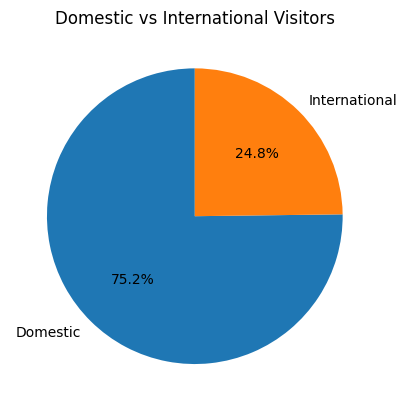

In [ ]:
visitor_type = tourism["Visitor_Type"].value_counts()

visitor_type.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Domestic vs International Visitors")
plt.ylabel("")
plt.show()

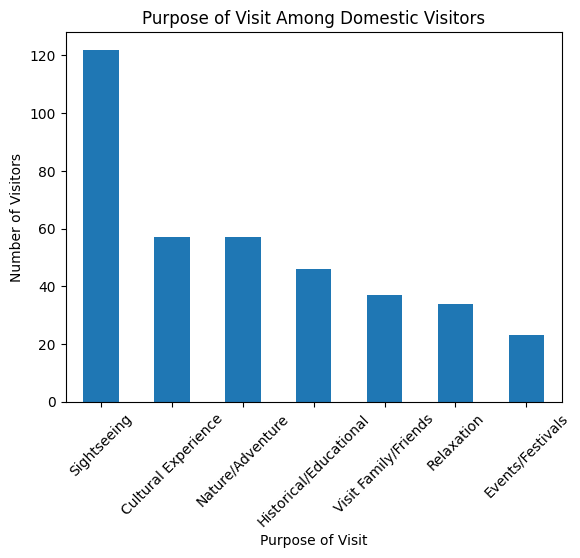

In [ ]:
domestic_purpose = tourism[tourism["Visitor_Type"] == "Domestic"]["Purpose_of_Visit"].value_counts()

domestic_purpose.plot(kind="bar")

plt.title("Purpose of Visit Among Domestic Visitors")
plt.xlabel("Purpose of Visit")
plt.ylabel("Number of Visitors")
plt.xticks(rotation=45)
plt.show()

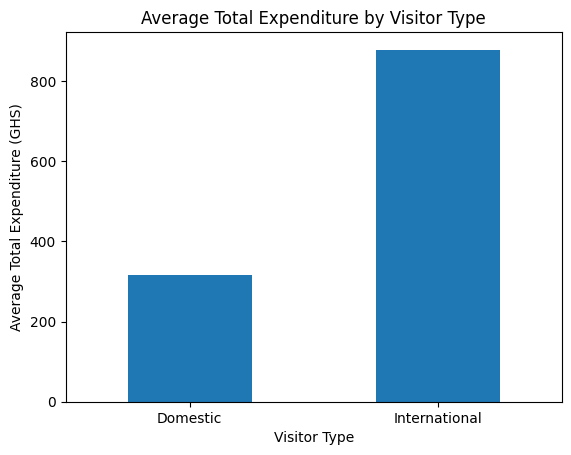

In [ ]:
tourism.groupby("Visitor_Type")["Total_Expenditure"].mean().plot(kind="bar")

plt.title("Average Total Expenditure by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Average Total Expenditure (GHS)")
plt.xticks(rotation=0)
plt.show()

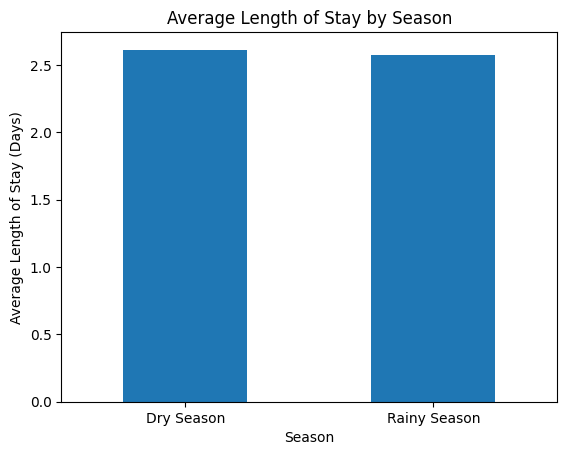

In [ ]:
# SEASON
tourism.groupby("Season")["Length_of_Stay_Days"].mean().plot(kind="bar")

plt.title("Average Length of Stay by Season")
plt.xlabel("Season")
plt.ylabel("Average Length of Stay (Days)")
plt.xticks(rotation=0)
plt.show()

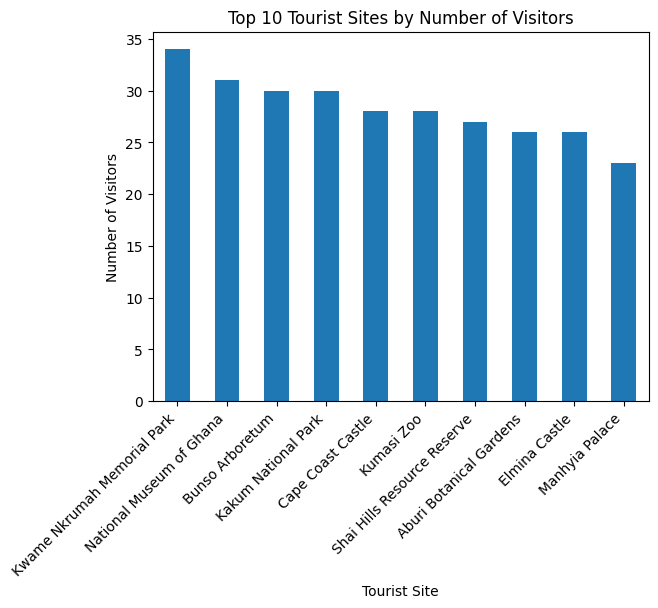

In [ ]:
top_sites = tourism["Site_Name"].value_counts().head(10)

top_sites.plot(kind="bar")

plt.title("Top 10 Tourist Sites by Number of Visitors")
plt.xlabel("Tourist Site")
plt.ylabel("Number of Visitors")
plt.xticks(rotation=45, ha="right")
plt.show()

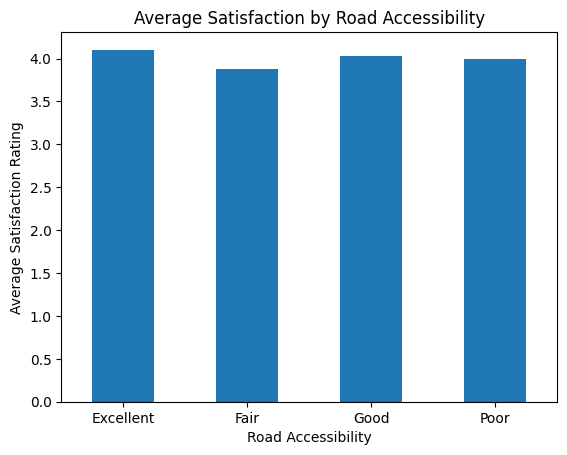

In [ ]:
import matplotlib.pyplot as plt

tourism.groupby("Accessibility_Road")["Satisfaction_Rating"].mean().plot(kind="bar")

plt.title("Average Satisfaction by Road Accessibility")
plt.xlabel("Road Accessibility")
plt.ylabel("Average Satisfaction Rating")
plt.xticks(rotation=0)
plt.show()

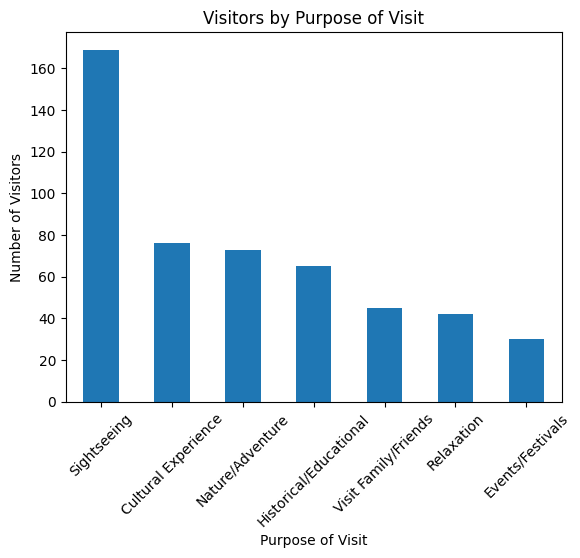

In [ ]:
import matplotlib.pyplot as plt

purpose_counts = tourism["Purpose_of_Visit"].value_counts()

purpose_counts.plot(kind="bar")

plt.title("Visitors by Purpose of Visit")
plt.xlabel("Purpose of Visit")
plt.ylabel("Number of Visitors")
plt.xticks(rotation=45)
plt.show()

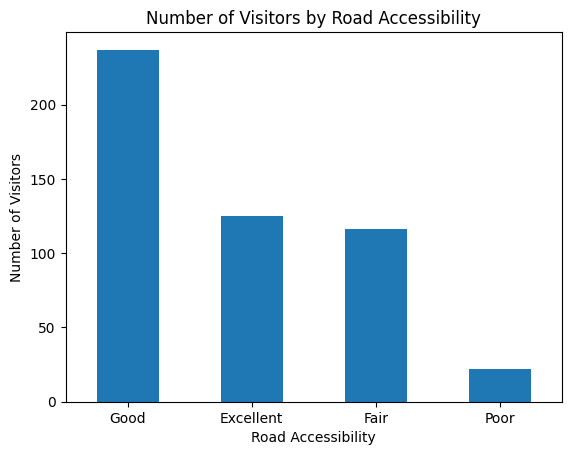

In [ ]:
road_visits.plot(kind="bar")

plt.title("Number of Visitors by Road Accessibility")
plt.xlabel("Road Accessibility")
plt.ylabel("Number of Visitors")
plt.xticks(rotation=0)
plt.show()

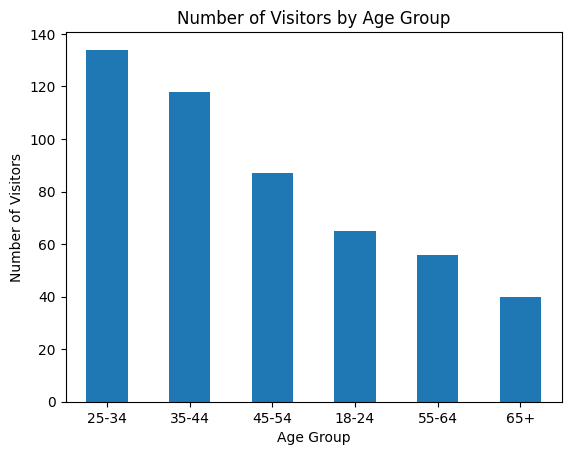

In [ ]:
age_visits.plot(kind="bar")

plt.title("Number of Visitors by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Visitors")
plt.xticks(rotation=0)
plt.show()

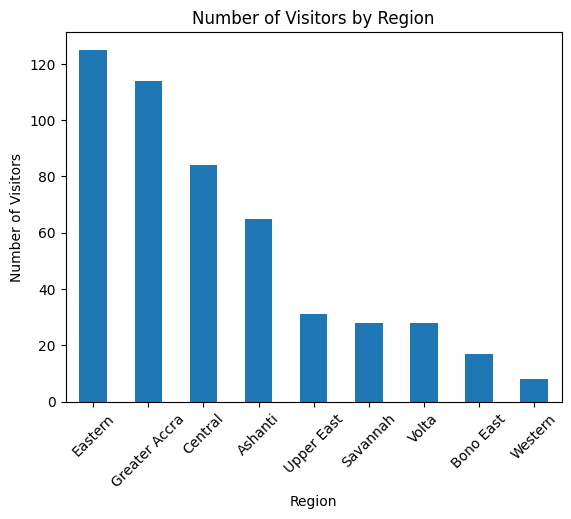

In [ ]:
region_visits.plot(kind="bar")

plt.title("Number of Visitors by Region")
plt.xlabel("Region")
plt.ylabel("Number of Visitors")
plt.xticks(rotation=45)
plt.show()

In [ ]:
december_visits = tourism[tourism["Month_of_Visit"] == "Dec"]
december_visits.shape[0]

59

In [ ]:
month_order = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

month_visits = tourism["Month_of_Visit"].value_counts().reindex(month_order)

month_visits

,count
Month_of_Visit,
Jan,35
Feb,37
Mar,49
Apr,46
May,32
Jun,37
Jul,43
Aug,38
Sep,38


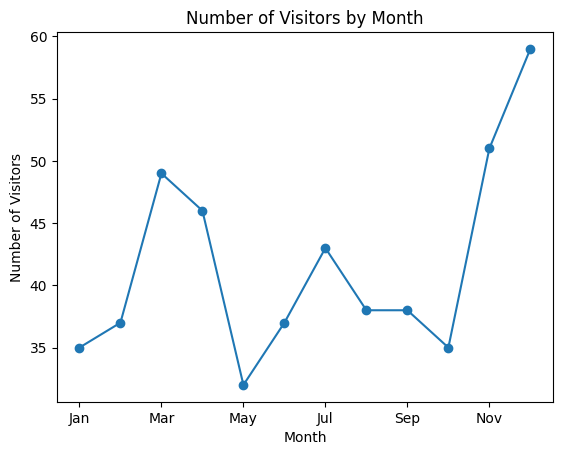

In [ ]:
month_visits.plot(kind="line", marker="o")

plt.title("Number of Visitors by Month")
plt.xlabel("Month")
plt.ylabel("Number of Visitors")
plt.xticks(rotation=0)
plt.show()

In [ ]:
month_visits = tourism["Month_of_Visit"].value_counts().reindex(month_order)
month_visits

,count
Month_of_Visit,
Jan,35
Feb,37
Mar,49
Apr,46
May,32
Jun,37
Jul,43
Aug,38
Sep,38


In [ ]:
# campaign or not

In [5]:
marketing_visits = tourism["Marketing_Visibility"].value_counts()
marketing_visits

,count
Marketing_Visibility,
High,206
Medium,203
Low,91


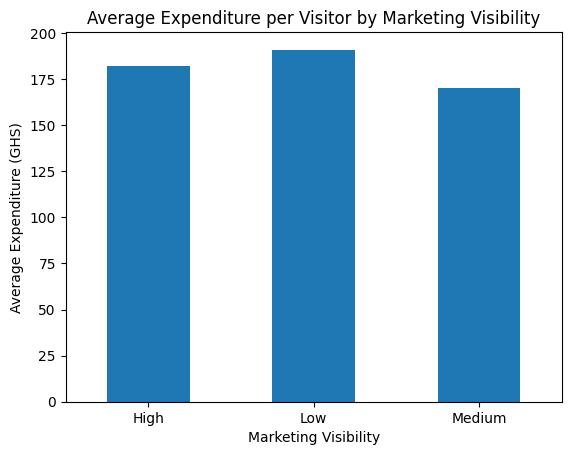

In [8]:
import matplotlib.pyplot as plt

marketing_average = tourism.groupby("Marketing_Visibility")["Average_Expenditure"].mean()

marketing_average.plot(kind="bar")

plt.title("Average Expenditure per Visitor by Marketing Visibility")
plt.xlabel("Marketing Visibility")
plt.ylabel("Average Expenditure (GHS)")
plt.xticks(rotation=0)
plt.show()

In [9]:
international_marketing = tourism[tourism["Visitor_Type"] == "International"].groupby(
    "Marketing_Visibility"
).size()
international_marketing

,0
Marketing_Visibility,
High,55
Low,26
Medium,43


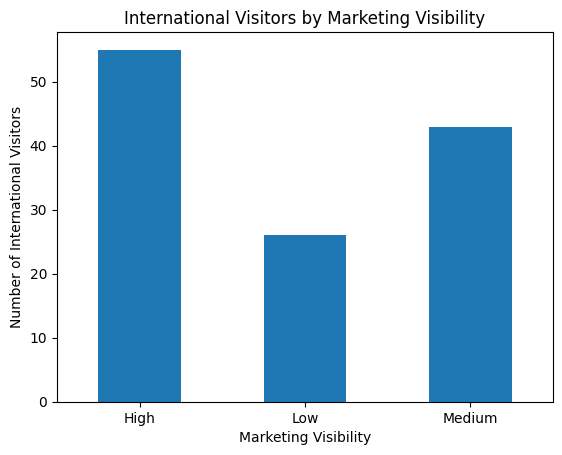

In [10]:
international_marketing.plot(kind="bar")

plt.title("International Visitors by Marketing Visibility")
plt.xlabel("Marketing Visibility")
plt.ylabel("Number of International Visitors")
plt.xticks(rotation=0)
plt.show()